In [1]:
from open_mastr import Mastr

db = Mastr()
db.download(data=["wind"])

2026-10-27 10:00:10,476 [INFO] 
--------->      open-MaStR started      <---------
Data will be written to the following database: sqlite:////Users/ramankp/.open-MaStR/data/sqlite/open-mastr.db
If you run into problems, try to delete the open-mastr directory & database and update the package by running 'pip install --upgrade open-mastr'

2026-10-27 10:00:10,476 [INFO] Starting MaStR documentation download from marktstammdatenregister.de.
2026-10-27 10:00:10,477 [INFO] Downloading MaStR documentation from https://www.marktstammdatenregister.de/MaStRHilfe/files/gesamtdatenexport/Dokumentation%20MaStR%20Gesamtdatenexport.zip
2026-10-27 10:00:10,923 [INFO] MaStR documentation was successfully downloaded to '/Users/ramankp/.open-MaStR/data/docs_download/Dokumentation MaStR Gesamtdatenexport_20261027.zip'. It took 0 seconds.
2026-10-27 10:00:11,041 [WARNING] No translation available for column 'AnlagenschluesselEeg_nv'
2026-10-27 10:00:11,054 [WARNING] No translation available for column 'Vo

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:03<00:00,  1.27s/ file]

2026-10-27 10:00:15,519 [INFO] Download is finished. It took 4 seconds.
2026-10-27 10:00:15,519 [INFO] MaStR was successfully downloaded to /Users/ramankp/.open-MaStR/data/xml_download.
2026-10-27 10:00:15,520 [INFO] 
Would you like to speed up the creation of your MaStR database?
Try our new parallelized processing by setting os.environ['USE_RECOMMENDED_NUMBER_OF_PROCESSES'] = True or configure your own number of processes via os.environ['NUMBER_OF_PROCESSES'] = your_number

2026-10-27 10:00:15,520 [INFO] Starting bulk download...
2026-10-27 10:00:15,523 [INFO] Processing file 'AnlagenEegWind.xml'...


2026-10-27 10:00:16,575 [WARNING] XML file has some columns that aren't present in the database table AnlagenEegWind. Trying to add the columns to the table. Additional XML columns: AnlagenschluesselEeg_nv
2026-10-27 10:00:16,576 [INFO] Added the following columns to database table AnlagenEegWind: AnlagenschluesselEeg_nv
2026-10-27 10:00:16,729 [INFO] Processing file 'EinheitenWind.xml'...
2026-10-27 10:00:19,435 [WARNING] XML file has some columns that aren't present in the database table EinheitenWind. Trying to add the columns to the table. Additional XML columns: VorlaeufigeRegelzonenDerEinheit
2026-10-27 10:00:19,436 [INFO] Added the following columns to database table EinheitenWind: VorlaeufigeRegelzonenDerEinheit
2026-10-27 10:00:19,805 [INFO] Bulk download was successful.


In [13]:
import matplotlib.pyplot as plt
import pandas as pd

wind = pd.read_sql("EinheitenWind", con=db.engine)
print(wind.shape)
print("VorlaeufigeRegelzonenDerEinheit" in wind.columns)

(44333, 84)
True


In [14]:
cols = [
    "EinheitMastrNummer",
    "EinheitBetriebsstatus",
    "WindAnLandOderAufSee",
    "Seelage",
    "VorlaeufigeRegelzonenDerEinheit",
    "Nettonennleistung",
    "Bruttoleistung",
    "Nabenhoehe",
    "Rotordurchmesser",
    "Hersteller",
    "Typenbezeichnung",
    "Laengengrad",
    "Breitengrad",
    "Bundesland",
    "Landkreis",
    "Postleitzahl",
    "Gemeinde",
    "Inbetriebnahmedatum",
    "DatumEndgueltigeStilllegung",
    "NameWindpark",
]
w = wind[cols]
w.head()

,EinheitMastrNummer,EinheitBetriebsstatus,WindAnLandOderAufSee,Seelage,VorlaeufigeRegelzonenDerEinheit,Nettonennleistung,Bruttoleistung,Nabenhoehe,Rotordurchmesser,Hersteller,Typenbezeichnung,Laengengrad,Breitengrad,Bundesland,Landkreis,Postleitzahl,Gemeinde,Inbetriebnahmedatum,DatumEndgueltigeStilllegung,NameWindpark
0,SEE940146675093,In Betrieb,Windenergie an Land,NaN,NaN,3000.0,3000.0,149.08,115.71,ENERCON GmbH,E-115,9.739374,51.270068,Hessen,Werra-Meißner-Kreis,34298,Gutsbezirk Kaufunger Wald,2017-09-01,NaT,Windpark Kreuzstein
1,SEE973767078653,In Betrieb,Windenergie an Land,NaN,NaN,3000.0,3000.0,135.40,115.70,ENERCON GmbH,E-115,10.299400,54.073831,Schleswig-Holstein,Segeberg,23824,Damsdorf,2017-09-28,NaT,Damsdorf
2,SEE914108319653,In Betrieb,Windenergie an Land,NaN,NaN,3000.0,3000.0,149.08,115.71,ENERCON GmbH,E-115,9.733069,51.272164,Hessen,Werra-Meißner-Kreis,34298,Gutsbezirk Kaufunger Wald,2017-09-04,NaT,Windpark Kreuzstein
3,SEE982417853618,In Betrieb,Windenergie an Land,NaN,NaN,3000.0,3000.0,149.08,115.71,ENERCON GmbH,E-115,9.748361,51.270462,Hessen,Werra-Meißner-Kreis,34298,Gutsbezirk Kaufunger Wald,2017-08-31,NaT,Windpark Kreuzstein
4,SEE913741454097,In Betrieb,Windenergie an Land,NaN,NaN,2400.0,2400.0,120.00,116.80,Nordex SE,N117,6.045546,51.029548,Nordrhein-Westfalen,Heinsberg,52525,Heinsberg,2017-01-11,NaT,Windpark Heinsberg Pütt


In [15]:
print(w["EinheitBetriebsstatus"].value_counts(), "\n")

summary = w.groupby("WindAnLandOderAufSee")["Nettonennleistung"].agg(["count", "sum"])
summary["GW"] = (summary["sum"] / 1e6).round(1)
print(summary, "\n")

print(w["VorlaeufigeRegelzonenDerEinheit"].value_counts(dropna=False).head(15), "\n")

print("Missing coordinates:\n", w[["Laengengrad", "Breitengrad"]].isna().sum(), "\n")
print(w[["Laengengrad", "Breitengrad", "Nabenhoehe"]].describe().round(2))

EinheitBetriebsstatus
In Betrieb                   32259
In Planung                    8838
Endgültig stillgelegt         3149
Vorübergehend stillgelegt       87
Name: count, dtype: int64 

                      count           sum     GW
WindAnLandOderAufSee                            
Windenergie an Land   42424  1.292473e+08  129.2
Windenergie auf See    1909  1.300874e+07   13.0 

VorlaeufigeRegelzonenDerEinheit
NaN          41043
1000001.0     1696
1001564.0     1048
1000010.0      475
1001572.0       71
Name: count, dtype: int64 

Missing coordinates:
 Laengengrad    1332
Breitengrad    1332
dtype: int64 

       Laengengrad  Breitengrad  Nabenhoehe
count     43001.00     43001.00    43487.00
mean          9.89        52.23      110.85
std           2.30         1.54       41.62
min          -3.62        47.53        1.00
25%           8.04        51.25       77.65
50%           9.38        52.23      105.00
75%          11.78        53.43      143.00
max          17.49        60

Text(0, 0.5, 'Latitude')

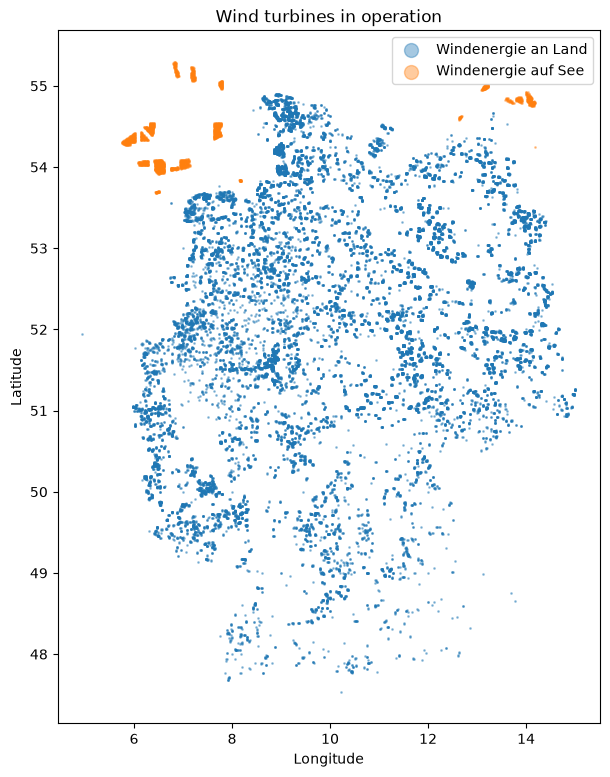

In [16]:
in_op = w[w["EinheitBetriebsstatus"] == "In Betrieb"]
plt.figure(figsize=(7, 9))
for kind, d in in_op.groupby("WindAnLandOderAufSee"):
    plt.scatter(d["Laengengrad"], d["Breitengrad"], s=1, alpha=0.4, label=kind)
plt.legend(markerscale=10)
plt.title("Wind turbines in operation")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

In [17]:
op = w[w["EinheitBetriebsstatus"] == "In Betrieb"]

summary = op.groupby("WindAnLandOderAufSee")["Nettonennleistung"].agg(["count", "sum"])
summary["GW"] = (summary["sum"] / 1e6).round(1)
print(summary, "\n")

print(pd.crosstab(op["Bundesland"], op["VorlaeufigeRegelzonenDerEinheit"]), "\n")

no_xy = w[w["Laengengrad"].isna()]
print(no_xy["EinheitBetriebsstatus"].value_counts(), "\n")
print("Capacity without coordinates (MW):", round(no_xy["Nettonennleistung"].sum() / 1000))
print(no_xy["Nettonennleistung"].describe().round(0))

                      count           sum    GW
WindAnLandOderAufSee                           
Windenergie an Land   30442  7.150140e+07  71.5
Windenergie auf See    1817  1.162874e+07  11.6 

VorlaeufigeRegelzonenDerEinheit  1000001.0  1000010.0  1001564.0  1001572.0
Bundesland                                                                 
Ausschließliche Wirtschaftszone          0          0         27          0
Baden-Württemberg                        0          0          0         24
Bayern                                   0          2         35          0
Brandenburg                             38          0          0          0
Hamburg                                  3          0          0          0
Hessen                                   0          6          5          0
Mecklenburg-Vorpommern                  67          0          0          0
Niedersachsen                            0         12         31          0
Nordrhein-Westfalen                      0    

In [18]:
print(
    no_xy.nlargest(5, "Nettonennleistung")[
        [
            "EinheitBetriebsstatus",
            "WindAnLandOderAufSee",
            "Bundesland",
            "Gemeinde",
            "Nettonennleistung",
            "NameWindpark",
        ]
    ],
    "\n",
)

is_off = w["WindAnLandOderAufSee"] == "Windenergie auf See"
ok_on = w["Laengengrad"].between(5.8, 15.1) & w["Breitengrad"].between(47.2, 55.1)
ok_off = w["Laengengrad"].between(3.3, 15.0) & w["Breitengrad"].between(53.3, 56.0)
has_xy = w["Laengengrad"].notna()

bad = w[has_xy & ((~is_off & ~ok_on) | (is_off & ~ok_off))]
print("Wrong coordinates:", len(bad), "units,", round(bad["Nettonennleistung"].sum() / 1000), "MW")
bad[
    [
        "EinheitBetriebsstatus",
        "WindAnLandOderAufSee",
        "Bundesland",
        "Gemeinde",
        "Laengengrad",
        "Breitengrad",
        "Nettonennleistung",
    ]
]

      EinheitBetriebsstatus WindAnLandOderAufSee           Bundesland  \
34721            In Betrieb  Windenergie an Land  Nordrhein-Westfalen   
34793            In Betrieb  Windenergie an Land  Nordrhein-Westfalen   
22671            In Betrieb  Windenergie an Land  Nordrhein-Westfalen   
22674            In Betrieb  Windenergie an Land  Nordrhein-Westfalen   
22679            In Betrieb  Windenergie an Land  Nordrhein-Westfalen   

      Gemeinde  Nettonennleistung          NameWindpark  
34721      NaN             5700.0         WP Aldenhoven  
34793      NaN             5700.0         WP Aldenhoven  
22671      NaN             3200.0  Eschweiler Fronhoven  
22674      NaN             3200.0  Eschweiler Fronhoven  
22679      NaN             3200.0  Eschweiler Fronhoven   

Wrong coordinates: 8 units, 32 MW


,EinheitBetriebsstatus,WindAnLandOderAufSee,Bundesland,Gemeinde,Laengengrad,Breitengrad,Nettonennleistung
295,Endgültig stillgelegt,Windenergie an Land,Nordrhein-Westfalen,Paderborn,8.833742,60.003844,1500.0
2547,Endgültig stillgelegt,Windenergie an Land,Rheinland-Pfalz,Monzelfeld,-3.622044,49.142675,2000.0
6929,Endgültig stillgelegt,Windenergie an Land,Schleswig-Holstein,Lindewitt,3.168577,54.688393,660.0
35205,In Betrieb,Windenergie an Land,Nordrhein-Westfalen,Sassenberg,4.943528,51.948940,5560.0
37604,In Planung,Windenergie an Land,Brandenburg,Werneuchen,17.492802,52.659028,6200.0
41612,In Planung,Windenergie an Land,Baden-Württemberg,Aalen,5.410572,54.105720,7200.0
42462,In Planung,Windenergie an Land,Nordrhein-Westfalen,Bad Wünnenberg,5.715594,47.992200,4260.0
44140,In Planung,Windenergie an Land,Niedersachsen,Luckau (Wendland),17.008540,52.934261,4800.0
